In [1]:
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os
import torchvision.transforms as transforms
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import timm
from transformers import AutoTokenizer, AutoModel

In [2]:
def set_seed(seed=59):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Set seed for reproducibility
set_seed(59)

In [3]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [4]:
if not os.path.exists("[Data]-VQA-Datasets.zip"):
    !gdown 1_EJLgV1TsE5avNjmx6aoKlszKmxOVcEh -O "[Data]-VQA-Datasets.zip"


In [5]:
import os
import zipfile

zip_path = "[Data]-VQA-Datasets.zip"

if os.path.isdir("data") and os.listdir("data"):
    print("Thư mục 'data' đã có, bỏ qua giải nén.")
else:
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")
    print("Đã giải nén xong.")


Thư mục 'data' đã có, bỏ qua giải nén.


In [6]:
class VQADataset(Dataset):
    def __init__(self, json_path, data_dir, transform=None, vocab=None):
        with open(json_path, 'r', encoding='utf-8') as f:
            self.data = json.load(f)

        self.data_dir = data_dir
        self.transform = transform
        self.vocab = vocab

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]

        # Load image
        img_path = os.path.join(self.data_dir, item['image_path'])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)

        # Question
        question = item['question']

        # Answer
        answer = item['answer']
        answer_idx = self.vocab.get(answer, -1)

        # Multiple answers for VQA Accuracy
        answers = item.get('answers', [answer])

        return {
            'image': image,
            'question': question,
            'answer': answer_idx,
            'raw_answer': answer,
            'answers': answers
        }

In [7]:
def get_transforms(img_size=224):
    train_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    val_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    return train_transform, val_transform

In [8]:
def build_answer_vocab(train_data, val_data, max_answers=10000):
    all_answers = []
    for item in train_data:
        all_answers.extend(item.get('answers', [item['answer']]))
    for item in val_data:
        all_answers.extend(item.get('answers', [item['answer']]))

    answer_counts = Counter(all_answers)
    unique_answers = list(answer_counts.keys())

    if len(unique_answers) > max_answers:
        unique_answers = [ans for ans, _ in answer_counts.most_common(max_answers)]

    vocab = {ans: idx for idx, ans in enumerate(sorted(unique_answers))}

    print(f"Built vocab: {len(vocab)} answers từ train+val (including all ground-truths)")
    return vocab

In [9]:
# Configuration
data_dir = 'data/vqav2'   # 'data/vqav2' or 'data/viinfographic'
batch_size = 32
img_size = 224

# English questions (VQAv2) -> English BERT, Vietnamese questions (ViInfographicVQA) -> PhoBERT
bert_model = 'bert-base-uncased' if data_dir.endswith('vqav2') else 'vinai/phobert-base'
max_len = 64
freeze_backbone = False   # False: fine-tune the whole network | True: train only the head

In [10]:
# Load data
train_transform, val_transform = get_transforms(img_size=img_size)

with open(os.path.join(data_dir, 'train.json'), 'r', encoding='utf-8') as f:
    train_data = json.load(f)
with open(os.path.join(data_dir, 'val.json'), 'r', encoding='utf-8') as f:
    val_data = json.load(f)

# Build vocab from train + val
vocab = build_answer_vocab(train_data, val_data)
num_classes = len(vocab)
idx_to_ans = {idx: ans for ans, idx in vocab.items()}

print(f"Number of classes: {num_classes}")

Built vocab: 4611 answers từ train+val (including all ground-truths)
Number of classes: 4611


In [11]:
# Create datasets
train_dataset = VQADataset(
    json_path=os.path.join(data_dir, 'train.json'),
    data_dir=data_dir,
    transform=train_transform,
    vocab=vocab
)

val_dataset = VQADataset(
    json_path=os.path.join(data_dir, 'val.json'),
    data_dir=data_dir,
    transform=val_transform,
    vocab=vocab
)

test_dataset = VQADataset(
    json_path=os.path.join(data_dir, 'test.json'),
    data_dir=data_dir,
    transform=val_transform,
    vocab=vocab
)

# DataLoaders
# num_workers=0: on Windows + Jupyter, worker processes (spawn) cannot re-import classes
# defined in the notebook (VQADataset) and the loader hangs. Use 4 on Colab/Linux.
train_loader = DataLoader(train_dataset, batch_size=batch_size,
                         shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size,
                       shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size,
                        shuffle=False, num_workers=0)

Question: What is on top of the skis?
Answer: snow


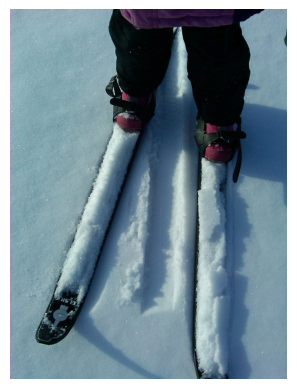

In [12]:
# Look at one training sample
sample = train_data[0]
print("Question:", sample['question'])
print("Answer:", sample['answer'])
plt.imshow(Image.open(os.path.join(data_dir, sample['image_path'])).convert('RGB'))
plt.axis('off')
plt.show()

In [13]:
# Load BERT tokenizer
bert_tokenizer = AutoTokenizer.from_pretrained(bert_model)
print(f"BERT model: {bert_model}")
print("BERT tokenizer loaded successfully")

BERT model: bert-base-uncased
BERT tokenizer loaded successfully


In [14]:
class GatedTanh(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.fc = nn.Linear(in_dim, out_dim)
        self.gate = nn.Linear(in_dim, out_dim)

    def forward(self, x):
        return torch.tanh(self.fc(x)) * torch.sigmoid(self.gate(x))

class TopDownAttention(nn.Module):
    def __init__(self, v_dim, q_dim, hidden_dim):
        super().__init__()
        self.fc = GatedTanh(v_dim + q_dim, hidden_dim)
        self.w_a = nn.Linear(hidden_dim, 1)

    def forward(self, v, q):
        # v: (B, N, D) patch features, q: (B, D) question feature
        # 1. repeat q for every patch and concatenate with v   -> (B, N, 2D)
        q_expand = q.unsqueeze(1).expand(-1, v.size(1), -1)         # (B, N, q_dim)

        # 2. score every patch: w_a(GatedTanh(.))               -> (B, N, 1)
        logits = self.w_a(self.fc(torch.cat([v, q_expand], dim=2)))  # (B, N, 1)

        # 3. softmax over the N patches                         -> alpha (B, N)
        alpha = logits.squeeze(2).softmax(dim=1)                    # (B, N)

        # 4. weighted sum of the patches                        -> v_hat (B, D)
        v_hat = (alpha.unsqueeze(2) * v).sum(dim=1)                 # (B, v_dim)
        return v_hat, alpha

class ViTBERTAttention(nn.Module):
    def __init__(self, num_classes, bert_model, bert_tokenizer, hidden_dim=512, img_size=224, max_len=64,
                 freeze_backbone=False):
        super().__init__()

        # Pretrained ViT: we keep ALL patch tokens instead of only [CLS]
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=True,
                                     num_classes=0, img_size=img_size)
        vit_output_dim = self.vit.num_features    # 768

        # Pretrained BERT
        self.tokenizer = bert_tokenizer
        self.bert = AutoModel.from_pretrained(bert_model)
        bert_output_dim = self.bert.config.hidden_size    # 768

        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            for param in self.vit.parameters():
                param.requires_grad = False
            for param in self.bert.parameters():
                param.requires_grad = False

        self.img_project = GatedTanh(vit_output_dim, hidden_dim)
        self.text_project = GatedTanh(bert_output_dim, hidden_dim)

        # Top-down attention: question -> weights over the 14x14 patches
        self.attention = TopDownAttention(hidden_dim, hidden_dim, hidden_dim)

        # Bottleneck: Fusion layer
        fusion_dim = hidden_dim * 2
        self.bottleneck = nn.Sequential(
            nn.Linear(fusion_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.5)
        )

        # Fully Connected (FC): Classifier
        self.classifier = nn.Linear(hidden_dim, num_classes)

        self.max_len = max_len

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            self.vit.eval()
            self.bert.eval()
        return self

    def encode_questions(self, questions, device):
        encoding = self.tokenizer(
            questions,
            padding=True,
            truncation=True,
            max_length=self.max_len,
            return_tensors='pt'
        )

        input_ids = encoding['input_ids'].to(device)
        attention_mask = encoding['attention_mask'].to(device)

        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        return outputs.last_hidden_state[:, 0, :]    # [CLS] embedding

    def forward(self, images, questions, return_attention=False):
        # Feature Extraction (FE)
        with torch.set_grad_enabled(torch.is_grad_enabled() and not self.freeze_backbone):
            ### COMPLETE THE FOLLOWING CODE ###   (drop the [CLS] token, keep the 196 patch features)
            tokens = self.vit.forward_features(images)
            patch_features = tokens[:, 1:, :]  # (B, 197, 768)
            text_features = self.encode_questions(questions, images.device)   # (B, 768)

        v = self.img_project(patch_features)    # (B, 196, 512)
        q = self.text_project(text_features)    # (B, 512)

        # Attention: weighted sum of the patches, guided by the question
        v_hat, alpha = self.attention(v, q)     # (B, 512), (B, 196)

        # Concatenate the attended image feature with the question feature,
        combined = torch.cat([v_hat, q], dim=1)
        # then apply the bottleneck and the classifier
        fused_features = self.bottleneck(combined)
        ### COMPLETE THE FOLLOWING CODE ###
        output = self.classifier(fused_features)

        if return_attention:
            return output, alpha
        return output

    

In [15]:
def compute_vqa_accuracy(prediction, ground_truth_answers):
    if not ground_truth_answers:
        return 0.0

    count = 0
    pred = prediction.lower().strip()
    for ans in ground_truth_answers:
        if ans.lower().strip() == pred:
            count += 1

    # 10 annotators: min(1, count / 3). A single annotator: exact match
    return min(1.0, count / min(3.0, len(ground_truth_answers)))

def levenshtein_distance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1

    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        distances_ = [i2+1]
        for i1, c1 in enumerate(s1):
            if c1 == c2:
                distances_.append(distances[i1])
            else:
                distances_.append(1 + min((distances[i1], distances[i1 + 1], distances_[-1])))
        distances = distances_
    return distances[-1]

def compute_anls(target, prediction):
    target = target.lower().strip()
    prediction = prediction.lower().strip()

    if not target or not prediction:
        return 0.0 if target != prediction else 1.0

    dist = levenshtein_distance(target, prediction)
    max_len = max(len(target), len(prediction))

    score = 1.0 - float(dist) / float(max_len)
    return score if score >= 0.5 else 0.0

def train_epoch(model, dataloader, criterion, optimizer, device, idx_to_ans):
    model.train()
    total_loss = 0
    sum_vqa_acc = 0
    total_samples = 0

    for batch in dataloader:
        images = batch['image'].to(device)
        questions = batch['question']
        answers = batch['answer'].to(device)
        raw_answers = batch['raw_answer']
        gt_answers_list = batch.get('answers', [[ans] for ans in raw_answers])

        # Handle list collation from DataLoader: [num_answers, batch_size] -> [batch_size, num_answers]
        if isinstance(gt_answers_list, list) and len(gt_answers_list) > 0 and isinstance(gt_answers_list[0], (list, tuple)):
            gt_answers_list = list(zip(*gt_answers_list))

        # Filter out samples với answers không có trong vocab (answer_idx = -1)
        valid_mask = answers != -1
        if not valid_mask.any():
            continue

        optimizer.zero_grad()
        outputs = model(images, questions)

        # Loss only on valid vocab samples
        v_outputs = outputs[valid_mask]
        v_answers = answers[valid_mask]
        loss = criterion(v_outputs, v_answers)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * v_answers.size(0)
        batch_size = images.size(0)
        total_samples += batch_size

        # Calculate VQA Accuracy for logging (on all samples in batch)
        _, predicted = outputs.max(1)
        for i in range(batch_size):
            pred_id = predicted[i].item()
            pred_text = idx_to_ans.get(pred_id, "")
            gt_list = gt_answers_list[i]
            sum_vqa_acc += compute_vqa_accuracy(pred_text, gt_list)

    avg_loss = total_loss / total_samples if total_samples > 0 else 0
    vqa_acc = 100. * sum_vqa_acc / total_samples if total_samples > 0 else 0

    return avg_loss, vqa_acc

def evaluate(model, dataloader, criterion, device, idx_to_ans):
    model.eval()
    total_loss = 0

    # Standard Accuracy (vocab only)
    correct_top1 = 0
    correct_top5 = 0
    total_valid_vocab = 0

    # VQA Accuracy (Top-1 & Top-5)
    sum_vqa_acc = 0
    sum_vqa_top5 = 0

    # ANLS
    sum_anls = 0
    total_samples = 0

    with torch.no_grad():
        for batch in dataloader:
            images = batch['image'].to(device)
            questions = batch['question']
            answers = batch['answer'].to(device)
            raw_answers = batch['raw_answer']
            gt_answers_list = batch.get('answers', [[ans] for ans in raw_answers])

            # Handle list collation from DataLoader: [num_answers, batch_size] -> [batch_size, num_answers]
            if isinstance(gt_answers_list, list) and len(gt_answers_list) > 0 and isinstance(gt_answers_list[0], (list, tuple)):
                gt_answers_list = list(zip(*gt_answers_list))

            batch_size = images.size(0)
            total_samples += batch_size

            outputs = model(images, questions)

            # --- Loss and Standard Accuracy ---
            valid_mask = answers != -1
            if valid_mask.any():
                v_outputs = outputs[valid_mask]
                v_answers = answers[valid_mask]
                loss = criterion(v_outputs, v_answers)
                total_loss += loss.item() * valid_mask.sum().item()

                _, predicted = v_outputs.max(1)
                correct_top1 += predicted.eq(v_answers).sum().item()

                _, top5_preds = v_outputs.topk(min(5, v_outputs.size(1)), 1)
                correct_top5 += (top5_preds == v_answers.view(-1, 1)).sum().item()

                total_valid_vocab += valid_mask.sum().item()

            # --- VQA Accuracy and ANLS ---
            _, top5_all = outputs.topk(min(5, outputs.size(1)), 1)

            for i in range(batch_size):
                pred_id = top5_all[i, 0].item()
                pred_text_top1 = idx_to_ans.get(pred_id, "")
                gt_list = gt_answers_list[i]

                # Top-1 VQA
                sum_vqa_acc += compute_vqa_accuracy(pred_text_top1, gt_list)

                # Top-5 VQA: max VQA score among top 5
                vqa_scores_top5 = [compute_vqa_accuracy(idx_to_ans.get(top5_all[i, j].item(), ""), gt_list) for j in range(top5_all.size(1))]
                sum_vqa_top5 += max(vqa_scores_top5)

                # ANLS (Top-1)
                sum_anls += compute_anls(raw_answers[i], pred_text_top1)

    avg_loss = total_loss / total_valid_vocab if total_valid_vocab > 0 else 0
    acc_top1 = 100. * correct_top1 / total_valid_vocab if total_valid_vocab > 0 else 0
    acc_top5 = 100. * correct_top5 / total_valid_vocab if total_valid_vocab > 0 else 0

    vqa_acc = 100. * sum_vqa_acc / total_samples if total_samples > 0 else 0
    vqa_top5 = 100. * sum_vqa_top5 / total_samples if total_samples > 0 else 0
    avg_anls = sum_anls / total_samples if total_samples > 0 else 0

    return avg_loss, acc_top1, acc_top5, vqa_acc, vqa_top5, avg_anls

In [16]:
PLOT_STYLE = {'font.family': 'serif',
              'font.serif': ['Times New Roman', 'Nimbus Roman', 'Liberation Serif', 'DejaVu Serif'],
              'mathtext.fontset': 'stix'}

def plot_training_history(history, save_path='training_history.pdf', model_name='Model'):
    with plt.rc_context(PLOT_STYLE):
        _plot_training_history(history, save_path, model_name)

def _plot_training_history(history, save_path, model_name):
    epochs = range(1, len(history['train_loss']) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Plot Loss
    ax1.plot(epochs, history['train_loss'], 'b-o', label='Train Loss', linewidth=2, markersize=4)
    ax1.plot(epochs, history['val_loss'], 'r-s', label='Val Loss', linewidth=2, markersize=4)
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.set_title(f'{model_name} - Training & Validation Loss', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)

    # Plot Accuracy
    ax2.plot(epochs, history['train_acc'], 'b-o', label='Train Acc', linewidth=2, markersize=4)
    ax2.plot(epochs, history['val_acc'], 'r-s', label='Val Acc', linewidth=2, markersize=4)
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Accuracy (%)', fontsize=12)
    ax2.set_title(f'{model_name} - Training & Validation Accuracy', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"Saved training history plot to {save_path}")
    plt.show()


def plot_final_results(train_acc, val_acc, test_vqa, save_path='final_results.pdf', model_name='Model'):
    with plt.rc_context(PLOT_STYLE):
        _plot_final_results(train_acc, val_acc, test_vqa, save_path, model_name)

def _plot_final_results(train_acc, val_acc, test_vqa, save_path, model_name):
    splits = ['Train', 'Validation', 'Test']
    accuracies = [train_acc, val_acc, test_vqa]
    colors = ['steelblue', 'coral', 'mediumseagreen']

    fig, ax = plt.subplots(figsize=(8, 6))

    bars = ax.bar(splits, accuracies, color=colors, edgecolor='black', linewidth=1.5, alpha=0.8)

    for bar, acc in zip(bars, accuracies):
        height = bar.get_height()
        ax.annotate(f'{acc:.2f}%',
                   xy=(bar.get_x() + bar.get_width() / 2, height),
                   xytext=(0, 3),
                   textcoords="offset points",
                   ha='center', va='bottom',
                   fontsize=12, fontweight='bold')

    ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
    ax.set_title(f'{model_name} - Final Results', fontsize=14, fontweight='bold')
    ax.set_ylim(0, max(accuracies) * 1.15)
    ax.grid(True, axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"Saved final results plot to {save_path}")
    plt.show()

In [17]:
# Initialize model
hidden_dim = 512

model = ViTBERTAttention(
    num_classes=num_classes,
    bert_model=bert_model,
    bert_tokenizer=bert_tokenizer,
    hidden_dim=hidden_dim,
    img_size=img_size,
    max_len=max_len,
    freeze_backbone=freeze_backbone
).to(device)

num_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params: {num_trainable/1e6:.1f}M")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 200.8M


In [18]:
# Loss and Optimizer
criterion = nn.CrossEntropyLoss()

# Differential learning rates: small for the pretrained backbones, larger for the new head
backbone_lr = 2e-5
head_lr = 1e-3

backbone_params = list(model.vit.parameters()) + list(model.bert.parameters())
backbone_ids = {id(p) for p in backbone_params}
head_params = [p for p in model.parameters() if id(p) not in backbone_ids]

param_groups = [{'params': head_params, 'lr': head_lr}]
if not freeze_backbone:
    param_groups.append({'params': backbone_params, 'lr': backbone_lr})
optimizer = torch.optim.AdamW(param_groups, weight_decay=0.01)

In [19]:
# Training configuration
num_epochs = 20

# Training history
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

In [20]:
# Training loop
best_vqa_acc = 0
best_epoch = 0

for epoch in range(num_epochs):
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device, idx_to_ans)

    # Val
    val_metrics = evaluate(model, val_loader, criterion, device, idx_to_ans)
    val_loss, val_acc, val_top5, val_vqa, val_vqa_top5, val_anls = val_metrics

    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_vqa)

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
    print(f"Val VQA Acc: {val_vqa:.2f}%, Val VQA Top5: {val_vqa_top5:.2f}%, Val ANLS: {val_anls:.4f}")

    # Save best model based on VQA Accuracy
    if val_vqa > best_vqa_acc:
        best_vqa_acc = val_vqa
        best_epoch = epoch + 1
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'vqa_acc': val_vqa,
            'vqa_top5': val_vqa_top5,
            'anls': val_anls,
        }, 'vit_bert_attention_best.pth')
        print(f"Saved best model with VQA Acc: {val_vqa:.2f}%")

KeyboardInterrupt: 

In [ ]:
# Load the best checkpoint (selected on the validation set) before testing
checkpoint = torch.load('vit_bert_attention_best.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best model from epoch {checkpoint['epoch'] + 1} (Val VQA Acc: {checkpoint['vqa_acc']:.2f}%)")

# Test evaluation
test_metrics = evaluate(model, test_loader, criterion, device, idx_to_ans)
test_loss, test_acc, test_top5, test_vqa, test_vqa_top5, test_anls = test_metrics
print(f"Test VQA Acc: {test_vqa:.2f}%, Test VQA Top5: {test_vqa_top5:.2f}%, Test ANLS: {test_anls:.4f}")

In [ ]:
plot_training_history(history, save_path='vit_bert_attention_history.pdf', model_name='ViT+BERT (attention)')
plot_final_results(history['train_acc'][-1], best_vqa_acc, test_vqa,
                  save_path='vit_bert_attention_results.pdf', model_name='ViT+BERT (attention)')

print("Training completed!")

In [ ]:
def visualize_attention(model, dataset, idx, save_path=None):
    model.eval()
    sample = dataset[idx]

    with torch.no_grad():
        output, alpha = model(sample['image'].unsqueeze(0).to(device), [sample['question']],
                              return_attention=True)
    pred_text = idx_to_ans.get(output.argmax(1).item(), "")

    # (1, 196) -> 14x14 grid -> upsample to the image size
    grid = int(alpha.size(1) ** 0.5)
    heatmap = alpha.reshape(1, 1, grid, grid)
    heatmap = F.interpolate(heatmap, size=(img_size, img_size), mode='bilinear', align_corners=False)[0, 0].cpu()

    image = Image.open(os.path.join(data_dir, dataset.data[idx]['image_path'])).convert('RGB')
    image = image.resize((img_size, img_size))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(image)
    ax1.axis('off')
    ax2.imshow(image)
    ax2.imshow(heatmap, cmap='jet', alpha=0.5)
    ax2.axis('off')
    fig.suptitle(f"Q: {sample['question']}\nGT: {sample['raw_answer']} | Pred: {pred_text}",
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

for idx in range(3):
    visualize_attention(model, test_dataset, idx, save_path=f'vit_bert_attention_{idx}.pdf')